# Detect differential item functioning with TIRT in R

**Experimental.** Analyze 800 simulated respondents in two groups. Each
person answers 12 pairs of statements. Three comparison cutpoints and
two statement loadings differ across groups. Group B also has different
trait means. The [Python tutorial](tirt_dif.ipynb) explains the TIRT model
and shows the generating values. Lee et al. (2021) studied both kinds of
DIF in forced-choice TIRT.

In [1]:
library(pyfcirt)

example <- load_example("tirt_dif", model = "TIRT")
head(example$responses)

  person_id block_id response
1         0      B01        0
2         0      B02        0
3         0      B03        1
4         0      B04        1
5         0      B05        0
6         0      B06        1


## Prepare the data

Register the design, responses, and person table. The reference group A has
zero trait means and unit residual SDs. Group B has its own means and
covariance. Multiplying a focal trait by a positive constant and dividing its
loadings by that constant gives the same response probabilities. Without
anchors, the model assumes most loadings are similar across groups. Response 1
prefers the first statement in a pair.

In [2]:
m <- model()
m$add_fc(example$design, example$responses, format = example$format,
         model = "TIRT", response_format = example$response_format)
m$set_population(group = "site", reference_group = "A",
                 person_data = example$person_data)
m$prepare()

## Fit loading and cutpoint DIF

The same formula applies to both parameters. The default Laplace prior
shrinks the estimated differences toward zero (Park & Casella, 2008).
Fitting uses BlackJAX by default.

In [3]:
m$available_covariate_targets(kind = "dif")

                target model     level kind predictor_level
1 fc.loading_magnitude  TIRT statement  dif          person
2         fc.cutpoints  TIRT      pair  dif          person


In [4]:
m$add_dif_terms(c("fc.loading_magnitude", "fc.cutpoints"), formula = "site")
m$fit(chains = 4L, random_seed = 33L)

## Compare groups

First check R-hat across the saved parameters. Then look at B03_1's loading
and the cutpoint for the comparison in B02. The table reports B minus A
and equal-tailed 95% posterior intervals.

In [5]:
diagnostics <- posterior::summarise_draws(as_draws(m), "rhat")
max(diagnostics$rhat, na.rm = TRUE)

[1] 1.026275


In [6]:
dif <- m$dif_summary(contrasts = list(site = c("A", "B")))
dif[dif$statement %in% "B03_1" | dif$pair %in% "B02_1 > B02_2",
    c("parameter", "statement", "pair", "mean", "lower", "upper")]

   parameter statement          pair       mean      lower      upper
5    loading     B03_1          NULL -0.2806421 -0.6472608 0.01225089
26  cutpoint      NULL B02_1 > B02_2  1.8926624  1.3436375 2.49722410


The figure shows all 12 comparison cutpoints and four selected loadings. Points are posterior means, and bars show equal-tailed 95% credible intervals. The dashed line marks equal parameters across groups.

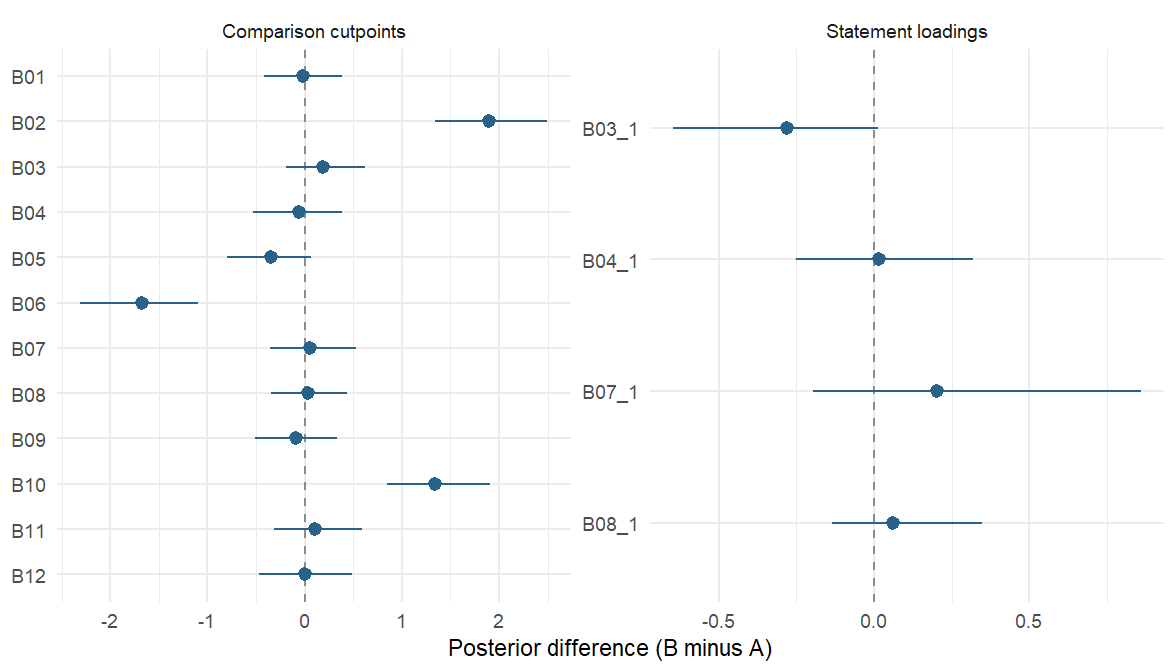

In [7]:
cutpoints <- subset(dif, parameter == "cutpoint")
loadings <- subset(dif, statement %in% c("B03_1", "B04_1", "B07_1", "B08_1"))
plot_data <- rbind(
  transform(cutpoints, label = vapply(units, function(x) x[[1L]], character(1)),
            panel = "Comparison cutpoints"),
  transform(loadings, label = unlist(statement), panel = "Statement loadings")
)

ggplot2::ggplot(plot_data, ggplot2::aes(x = mean, y = label, xmin = lower, xmax = upper)) +
  ggplot2::geom_vline(xintercept = 0, linetype = "dashed", colour = "grey55") +
  ggplot2::geom_pointrange(orientation = "y", colour = "#28628a") +
  ggplot2::facet_wrap(~ panel, scales = "free") +
  ggplot2::scale_y_discrete(limits = rev) +
  ggplot2::labs(x = "Posterior difference (B minus A)", y = NULL) +
  ggplot2::theme_minimal(base_size = 12)


The interval for the B02 cutpoint difference lies above zero. The estimated
loading for B03_1 is lower in group B, and its interval includes zero.

## Anchor a comparison

On a fresh model, anchor both statement loadings and the cutpoint in B01
to estimate common values across the two groups.

```r
anchored <- model()
anchored$add_fc(example$design, example$responses, format = example$format,
                model = "TIRT", response_format = example$response_format)
anchored$set_population(group = "site", reference_group = "A",
                        person_data = example$person_data)
anchored$prepare()
anchored$add_dif_terms(
  list(
    "fc.loading_magnitude" = list(anchors = c("B01_1", "B01_2")),
    "fc.cutpoints" = list(
      anchors = data.frame(block_id = "B01", statement_1 = "B01_1", statement_2 = "B01_2")
    )
  ),
  formula = "site"
)
```

The [R API reference](../reference/r_api.md#differential-item-functioning)
describes prior overrides, formulas with interactions, and conditional contrasts.


## References

Lee, P., Joo, S.-H., & Stark, S. (2021). Detecting DIF in multidimensional forced choice measures using the Thurstonian item response theory model. *Organizational Research Methods, 24*(4), 739–771. [https://doi.org/10.1177/1094428120959822](https://doi.org/10.1177/1094428120959822)

Park, T., & Casella, G. (2008). The Bayesian lasso. *Journal of the American Statistical Association, 103*(482), 681–686. [https://doi.org/10.1198/016214508000000337](https://doi.org/10.1198/016214508000000337)